In [77]:
import numpy as np
import pandas as pd

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

## BUSINESS SCENARIO: WHY ARE HOTEL BOOKINGS GETTING CANCELLED?

* Content :
* This data set contains booking information for a city hotel and a resort hotel, and includes information such as when the booking was made, length of stay, the number of adults, children, and/or babies, and the number of available parking spaces, among other things.

In [79]:
df = pd.read_csv(r"C:\Users\lenovo\Downloads\hotel_bookings.csv.zip")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [80]:
df1 = df.copy()
df2 = df.copy()

In [81]:
df1.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [82]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [83]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## Handaling null values

Children

In [84]:
df1['children'].isna().sum()

np.int64(4)

In [85]:
df1['children'] = df1['children'].ffill()

In [86]:
df1['children'] = df1['children'].bfill()

In [87]:
df1['children'].isnull().sum()

np.int64(0)

Country

In [88]:
df1['country'].isnull().sum()

np.int64(488)

In [89]:
df1['country'] = df1['country'].fillna('Unknown')

In [90]:
df1['country'].isnull().sum()

np.int64(0)

Agent

In [91]:
df1['agent'].mean()

np.float64(86.69338185346919)

In [92]:
df1['agent'].median()

np.float64(14.0)

In [93]:
df1.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [94]:
df1['agent'] = df1['agent'].fillna(df1['agent'].mean())

In [95]:
df1['agent'].isnull().sum()

np.int64(0)

Company

In [96]:
# 119390 - Total entries
# 112593 - null values
119390 - 112593  #(NOT NULL) = 6797

6797

In [97]:
df1['company'].isnull().sum()

np.int64(112593)

In [98]:
df1['company'].mean()

np.float64(189.26673532440782)

In [99]:
df1['company'].median()

np.float64(179.0)

In [100]:
df1['company'].mode()

0    40.0
Name: company, dtype: float64

In [101]:
df3 = df1.copy()

In [102]:
df1 = df1.drop(columns='company')


In [103]:
df1.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

## Part - A 
## Univariate Analysis

Q1. The hotel reservation team wants to understand how far in advance customers typically 
make their bookings. Create a suitable Seaborn visualization to analyze the distribution of 
booking lead time. Determine whether most customers book rooms well in advance or closer 
to their arrival dates

In [104]:
df1['lead_time']

0         342
1         737
2           7
3          13
4          14
         ... 
119385     23
119386    102
119387     34
119388    109
119389    205
Name: lead_time, Length: 119390, dtype: int64

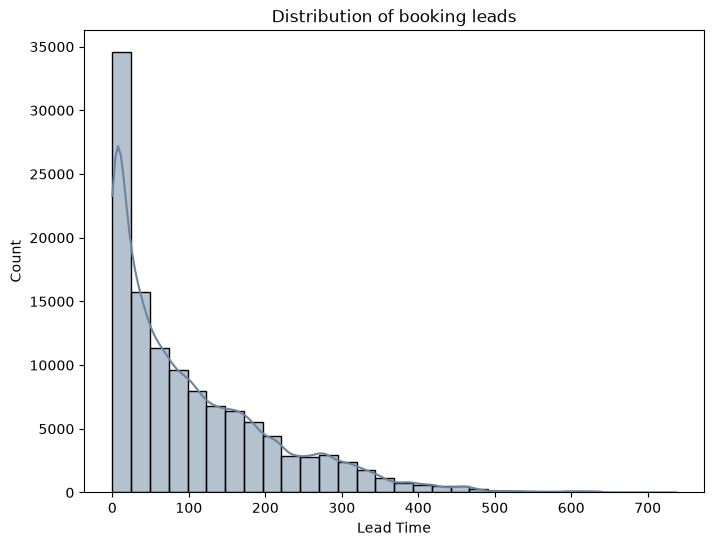

In [176]:
plt.figure(figsize=(8,6))
sns.histplot(data=df1,x=df1['lead_time'],bins=30,kde=True,color="#6A85A0")

plt.title("Distribution of booking leads")
plt.xlabel("Lead Time")
plt.show()


Insight: 
* Most guests book their hotel within a few weeks or months of arrival. Fewer people book far in advance.
* The tallest bars show when most bookings happen. The long, low tail on the right shows that a few guests book
   much   earlier.

Q2. The revenue management team wants to understand the pricing structure of hotel 
rooms. Analyze the distribution of Average Daily Rate (ADR) and determine whether room 
prices are concentrated within a particular price range. Identify any unusually high or low 
ADR values

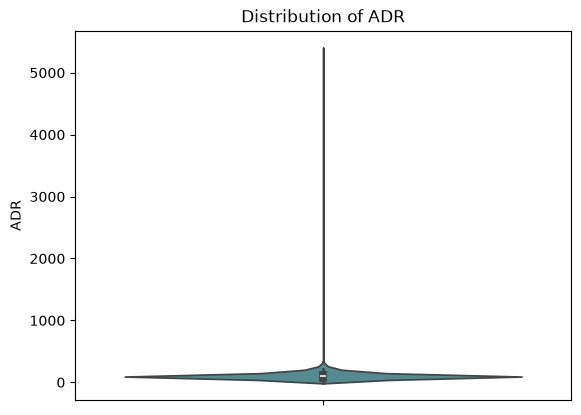

In [128]:
sns.violinplot(data=df1,y=df1['adr'],color="#47959C")           ## adr : average daily rate

plt.title("Distribution of ADR")
plt.ylabel("ADR")
plt.show()

Insight: Most bookings have a low to moderate ADR. Only a few bookings have very high ADR, so the distribution is concentrated at the lower prices with a long tail toward higher prices.

Q3. Management wants to understand the composition of hotel bookings. Visualize the 
number of bookings received by City Hotel and Resort Hotel. Identify which hotel type 
receives the highest number of bookings. 

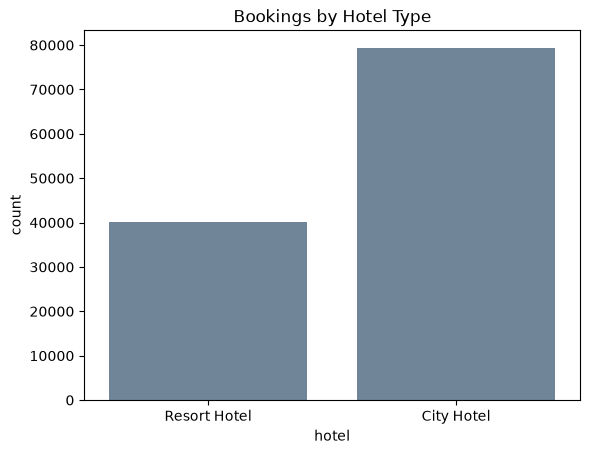

In [175]:
sns.countplot(data=df1, x="hotel",color="#6A85A0")
plt.title("Bookings by Hotel Type")
plt.show()

Insight: The city hotel recieves more bookings compared to resort hotel

Q4. The operations team wants to understand customer stay patterns. Analyze the 
distribution of weekend nights booked by guests. Determine whether customers generally 
book short weekend stays or longer stays.

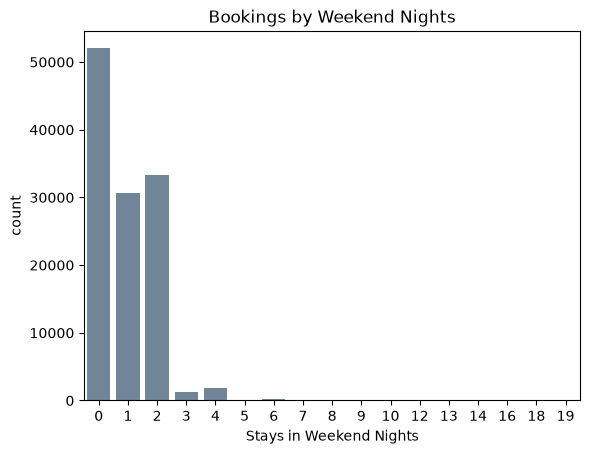

In [109]:
sns.countplot(data=df1, x="stays_in_weekend_nights",color="#6A85A0")
plt.title("Bookings by Weekend Nights")
plt.xlabel('Stays in Weekend Nights')
plt.show()

Insight: Most bookings include 0–2 weekend nights, with bookings of 0 weekend nights being the most common. Stays of 3 or more weekend nights are very less , and very long weekend stays are rare.

Q5. The hotel director wants a clear picture of overall booking cancellations. Visualize the 
proportion of cancelled and non-cancelled reservations. Calculate the overall cancellation 
rate and explain its business significance. 

In [139]:
status = df1["is_canceled"].map({0: "Not canceled",1: "Canceled"})

Overall cancellation rate: 37.04%


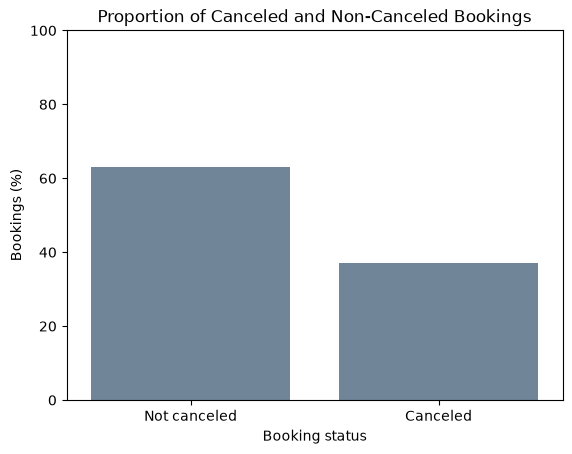

In [174]:
percent = status.value_counts(normalize=True).reindex(["Not canceled", "Canceled"]) * 100
    
print(f"Overall cancellation rate: {percent['Canceled']:.2f}%")

# Plot the percentages
sns.barplot(x=percent.index, y=percent.values, color="#6A85A0")
plt.title("Proportion of Canceled and Non-Canceled Bookings")
plt.xlabel("Booking status")
plt.ylabel("Bookings (%)")
plt.ylim(0, 100)
plt.show()

Insight: About 37% of bookings were canceled, while 63% were not. That is roughly 1 in 3 bookings canceled, which can leave rooms empty and reduce revenue. The hotel should consider cancellations when forecasting occupancy.

Q6. The guest experience team wants to understand how frequently customers make 
special requests during booking. Analyze the distribution of the number of special requests 
and identify whether most customers make no requests, a few requests, or multiple 
requests. 

In [112]:
df1['total_of_special_requests']

0         0
1         0
2         0
3         0
4         1
         ..
119385    0
119386    2
119387    4
119388    0
119389    2
Name: total_of_special_requests, Length: 119390, dtype: int64

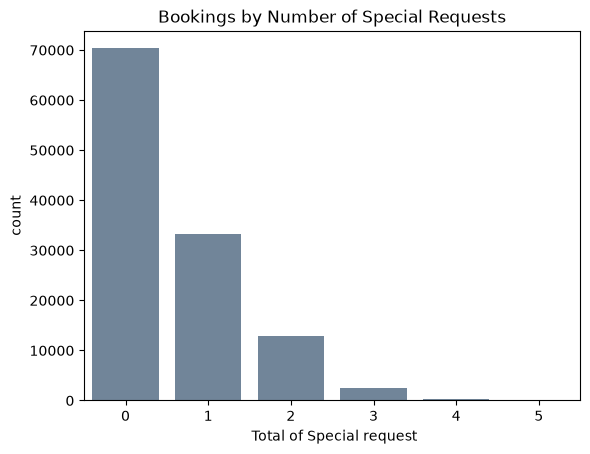

In [ ]:
sns.countplot(data=df, x="total_of_special_requests",color="#'6A85A0'")
plt.title("Bookings by Number of Special Requests")
plt.xlabel(" Total of Special request")
plt.show()

Insight : Most of the customers make no request than multiple requests

### PART B: BIVARIATE ANALYSIS

Q7. Management suspects that booking cancellation rates differ between City Hotel and 
Resort Hotel. Compare cancellation rates across the two hotel types using an appropriate 
Seaborn visualization. Which hotel type has the higher cancellation rate? 

In [114]:
labels = df1["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


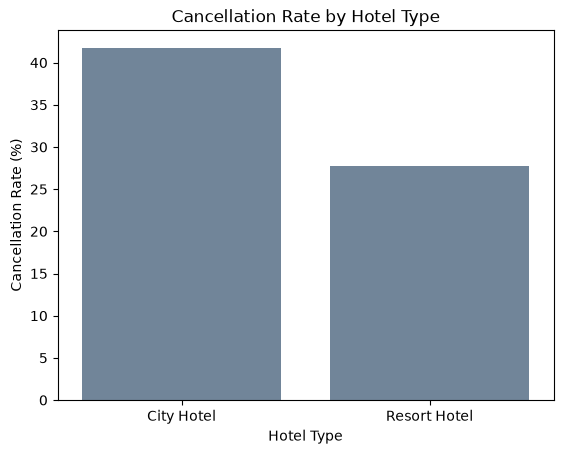

In [143]:

rates = df.groupby("hotel")["is_canceled"].mean() * 100       # Calculate cancellation percentage for each hotel
print(rates)


sns.barplot(x=rates.index, y=rates.values,color='#6A85A0')
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

Insight : City hotel has highter cancellation rate  than resort hotel


Q8. The reservation team believes customers who book rooms far in advance may be more 
likely to cancel. Investigate the relationship between booking lead time and cancellation 
status. Does the visualization support this concern?

In [116]:
df1["cancel_status"] = df1["is_canceled"].map({0: "Not canceled",1: "Canceled"})

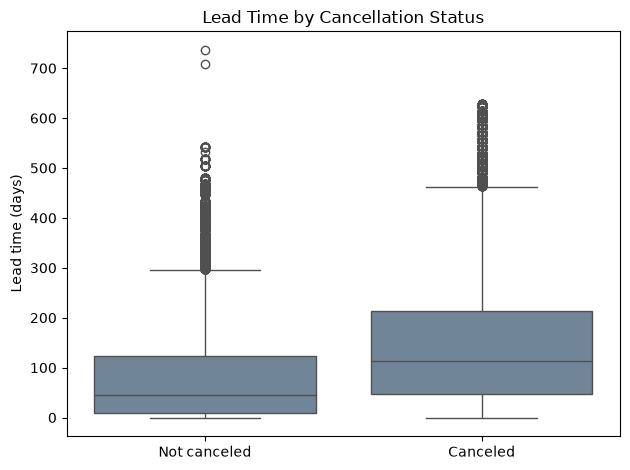

In [144]:
sns.boxplot(data=df1, x="cancel_status", y="lead_time",color='#6A85A0')
plt.title("Lead Time by Cancellation Status")
plt.xlabel("")
plt.ylabel("Lead time (days)")
plt.tight_layout()
plt.show()

Insight: The cancellation rate is generally higher for bookings made further in advance. This supports the team’s concern that early bookings are more likely to be canceled.But the boxplot does not prove that booking early causes cancellation

Q9. The revenue management team suspects that room pricing may be associated with 
booking cancellations. Compare the distribution of Average Daily Rate (ADR) between 
cancelled and non-cancelled bookings. What differences do you observe?

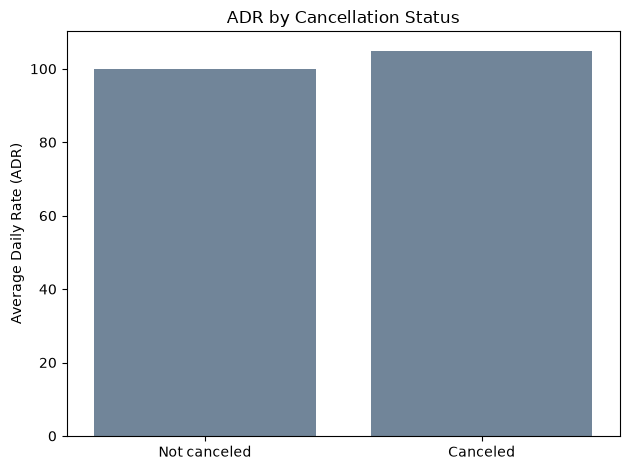

In [145]:
sns.barplot(data=df1, x="cancel_status", y="adr",errorbar=None,color='#6A85A0')
plt.title("ADR by Cancellation Status")
plt.xlabel("")
plt.ylabel("Average Daily Rate (ADR)")
plt.tight_layout()
plt.show()

Insight: Canceled bookings tend to have a slightly higher ADR, but the two groups overlap. This suggests ADR may be associated with cancellations, though ADR alone does not explain them

Q10. The marketing department wants to understand whether cancellation behavior differs 
across booking market segments. Compare cancellation rates across market segments and 
identify which segments have the highest and lowest cancellation rates.

In [146]:
rates = df1.groupby("market_segment")["is_canceled"].mean() * 100
rates = rates.sort_values(ascending=False)

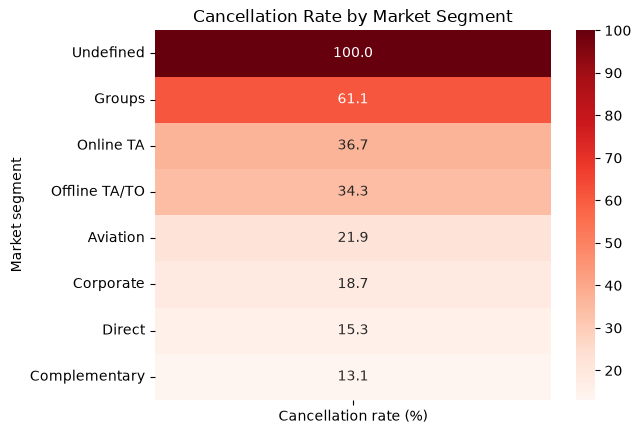

In [153]:
sns.heatmap(
    rates.to_frame(name="Cancellation rate (%)"),
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Cancellation Rate by Market Segment")
plt.ylabel("Market segment")
plt.show()

Insight: The heatmap shows that cancellation rates differ across market segments. The darkest cell has the highest rate, while the lightest has the lowest. Marketing can focus on reducing cancellations in the segment with the highest rate.

Q11. Management wants to understand whether the length of a guest's stay is associated 
with room pricing. Analyze the relationship between total nights stayed and Average Daily 
Rate (ADR). Do customers booking longer stays generally pay higher or lower daily room 
rates?

In [157]:
df1["total_nights"] = (df1["stays_in_weekend_nights"] + df1["stays_in_week_nights"])   

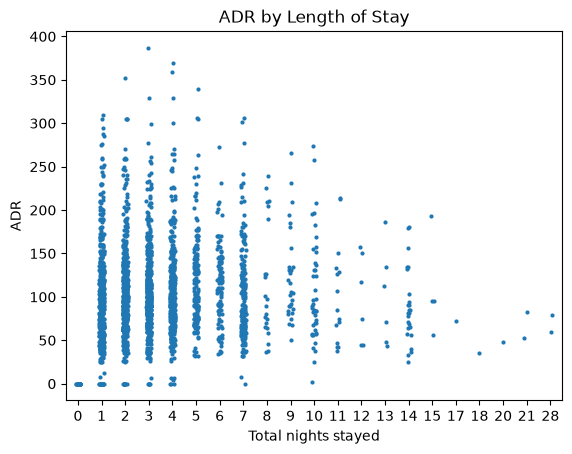

In [160]:
plot_data = df1.sample(min(3000, len(df1)), random_state=1)

sns.stripplot(
    data=plot_data,
    x="total_nights",
    y="adr",
    jitter=True,
    size=3)
    

plt.title("ADR by Length of Stay")
plt.xlabel("Total nights stayed")
plt.ylabel("ADR")
plt.show()

Insight : Guests staying longer tend to pay slightly less per night, but room prices still vary a lot.

Q12. The customer relationship team suspects that cancellation rates vary across customer 
categories. Compare cancellation rates among different customer types, such as Transient, 
Contract, Transient-Party, and Group customers. Which customer types appear more likely 
to cancel reservations?

customer_type
Contract           30.961727
Group              10.225303
Transient          40.746320
Transient-Party    25.429868
Name: is_canceled, dtype: float64


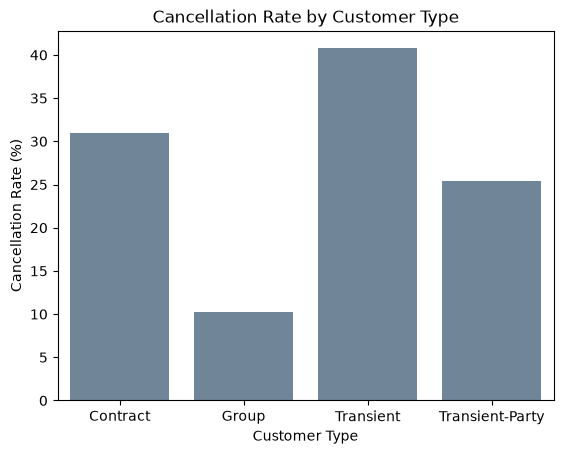

In [161]:
rates = df.groupby("customer_type")["is_canceled"].mean() * 100
print(rates)


sns.barplot(x=rates.index, y=rates.values,color='#6A85A0')
plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.show()

Insight: The Transient customers are more likely to canceel reservation compared to other customers

## PART C: MULTIVARIATE ANALYSIS 

Q13. Hotel management suspects that cancellation patterns across market segments may 
differ between City Hotel and Resort Hotel. Create a Seaborn visualization comparing 
cancellation rates across market segments, separated by hotel type. Which hotel and market 
segment combinations appear most vulnerable to cancellations?


In [162]:
rates = df1.groupby( ["hotel", "market_segment"])["is_canceled"].mean().reset_index()
rates["is_canceled"] = rates["is_canceled"] * 100

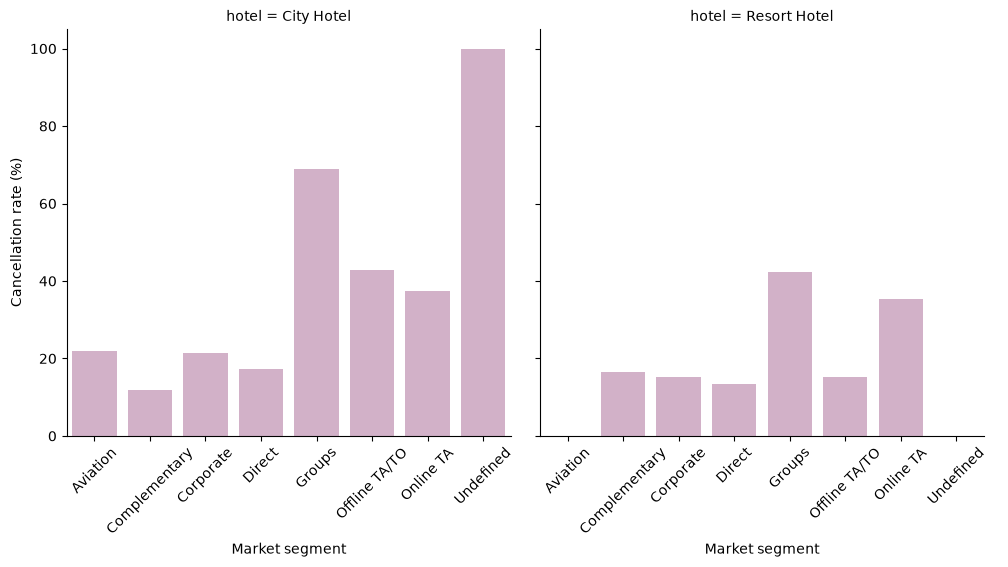

In [164]:
g = sns.catplot(
    data=rates,
    x="market_segment",
    y="is_canceled",
    col="hotel",
    kind="bar",
    color="#D8ABCA"
)

g.set_axis_labels("Market segment", "Cancellation rate (%)")
g.set_xticklabels(rotation=45)
plt.show()

Insight: City Hotel–Undefined appears highest so City Hotel–Groups has a high cancellation rate.

Q14. The revenue management team believes that booking lead time and room pricing 
together may be associated with cancellation behavior. Analyze the relationship between 
lead time, Average Daily Rate (ADR), and cancellation status. Do cancelled bookings tend to 
cluster within particular lead-time and price combinations?

In [ ]:
df1['cancel_status']

0         Not canceled
1         Not canceled
2         Not canceled
3         Not canceled
4         Not canceled
              ...     
119385    Not canceled
119386    Not canceled
119387    Not canceled
119388    Not canceled
119389    Not canceled
Name: cancel_status, Length: 119390, dtype: str

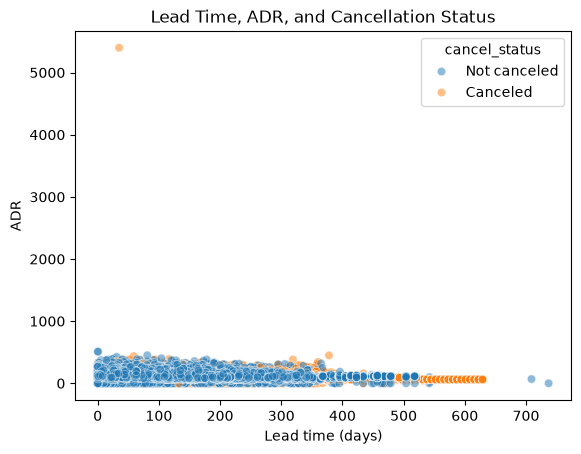

In [169]:
sns.scatterplot(
    data=df1,
    x="lead_time",
    y="adr",
    hue="cancel_status",
    alpha=0.5
)

plt.title("Lead Time, ADR, and Cancellation Status")
plt.xlabel("Lead time (days)")
plt.ylabel("ADR")
plt.show()

Insight :More canceled bookings appear among guests who booked far in advance. Canceled bookings have a wide range of prices, so there isn’t one clear price pattern.

Q15. Management wants to investigate whether deposit policies and customer types 
together are associated with booking cancellations. Compare cancellation rates across 
different combinations of deposit type and customer type. Which combinations show the 
highest cancellation rates?

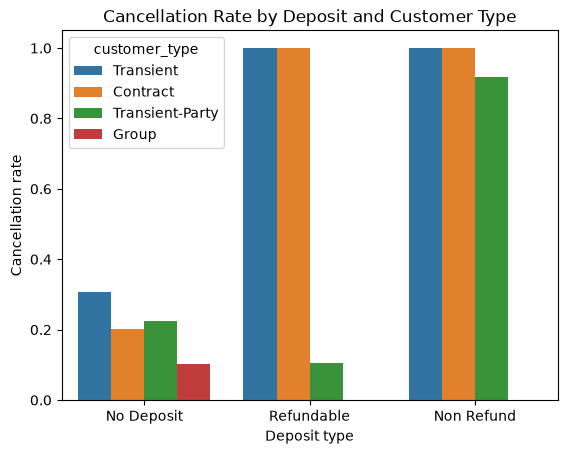

In [172]:
sns.barplot(
    data=df1,
    x="deposit_type",
    y="is_canceled",
    hue="customer_type",
    errorbar=None
)


plt.title("Cancellation Rate by Deposit and Customer Type")
plt.xlabel("Deposit type")
plt.ylabel("Cancellation rate")
plt.show()

Insight: Bookings with a Non Refund deposit, especially those from Transient customers, have the highest cancellation rates. This suggests cancellation patterns vary with both deposit policy and customer type.

Q16. The operations team wants to understand whether the relationship between length of 
stay and room pricing differs across hotel types. Visualize total nights stayed, Average Daily 
Rate (ADR), and hotel type in a single analysis. What differences can you identify between 
City Hotel and Resort Hotel? 

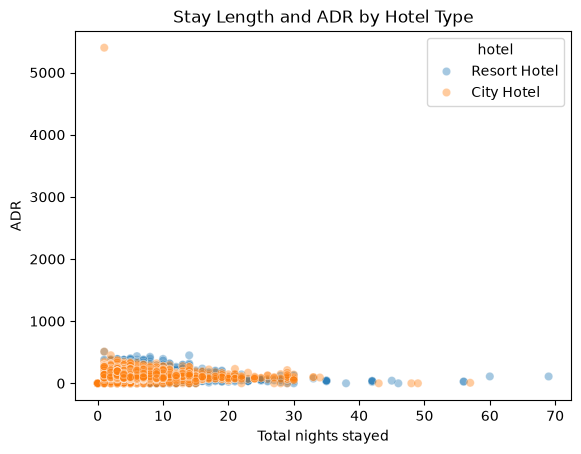

In [ ]:
sns.scatterplot(
    data=df1,
    x="total_nights",
    y="adr",
    hue="hotel",
    alpha=0.4
)

plt.title("Stay Length and ADR by Hotel Type")
plt.xlabel("Total nights stayed")
plt.ylabel("ADR")
plt.show()

Insight: Resort Hotel bookings generally have longer stays, while City Hotel bookings are more concentrated around shorter stays. ADR varies widely for both hotel types, so stay length alone does not clearly determine the price.

Q17. The leadership team suspects that customers booking far in advance at higher room 
rates may be more likely to cancel, but this relationship could differ between hotel types. 
Create a multivariate Seaborn visualization incorporating booking lead time, Average Daily 
Rate (ADR), hotel type, and cancellation status. Identify booking segments associated with 
higher cancellation rates and explain the observed patterns. 


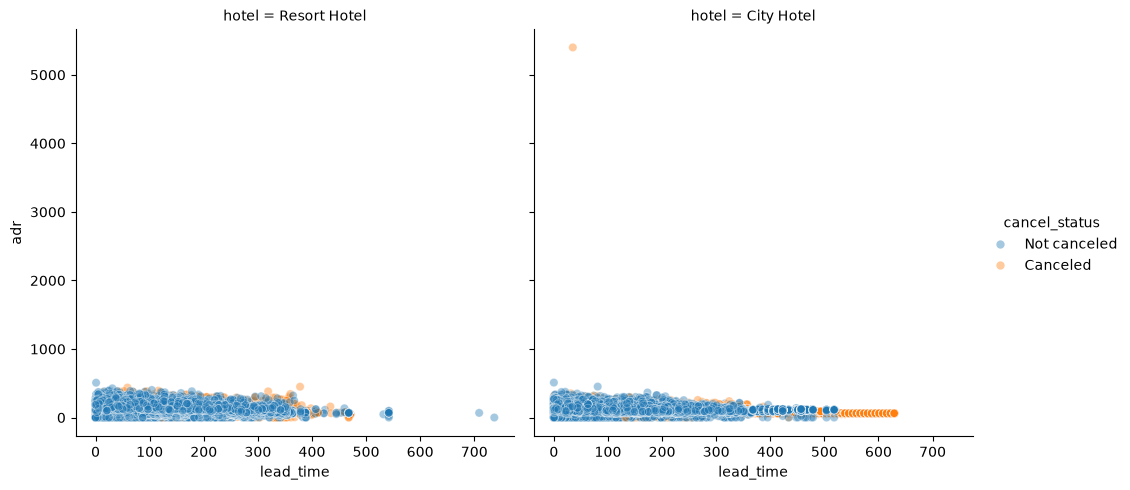

In [ ]:
sns.relplot(                       ## Relational plot (relplot)
    data=df1,
    x="lead_time",
    y="adr",
    hue="cancel_status",
    col="hotel",
    kind="scatter",
    alpha=0.4
)

plt.show()

Insight: Canceled bookings appear across many ADR levels, but are more noticeable among bookings made far in advance Mostly in city hotel

## Key Findings :
* City Hotel had a higher cancellation rate than Resort Hotel
* ADR varied widely, so room price alone did not clearly explain cancellations
* Canceled bookings were often made further in advance

## Recommendation :

* confirm early booking 
* Make the most canceled segment much more relaible
* check canceletion regurlarly and inform customers about the availability in rooms 


## Potential implications for revenue and occupancy planning : 
When guests cancel, the hotel may have empty rooms and earn less than expected. Looking at past bookings can help managers estimate how many guests will arrive, remind guests who may be more likely to cancel, and rebook rooms quickly when plans change